In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df_int = pd.read_excel(r'C:\Users\hkhakan\OneDrive - Clemson University\Documents\GitHub\multi_period_disaster_logistics\posteriors (CK equations)\Data.xlsx', sheet_name="intensity", header=None, index_col=None) 
p_int = df_int.values
print("p_int: \n", p_int)

df_locx = pd.read_excel(r'C:\Users\hkhakan\OneDrive - Clemson University\Documents\GitHub\multi_period_disaster_logistics\posteriors (CK equations)\Data.xlsx', sheet_name="locx", header=None, index_col=None) 
p_locx = df_locx.values
print("p_locx: \n", p_locx)

print("homa")

df_locy = pd.read_excel(r'C:\Users\hkhakan\OneDrive - Clemson University\Documents\GitHub\multi_period_disaster_logistics\posteriors (CK equations)\Data.xlsx', sheet_name="locy-det", header=None, index_col=None) 
p_locy = df_locy.values
print("p_locy: \n", p_locy)

p_int: 
 [[1.   0.   0.   0.   0.   0.  ]
 [0.11 0.83 0.06 0.   0.   0.  ]
 [0.   0.15 0.6  0.25 0.   0.  ]
 [0.   0.   0.04 0.68 0.28 0.  ]
 [0.   0.   0.   0.18 0.79 0.03]
 [0.   0.   0.   0.   0.5  0.5 ]]
p_locx: 
 [[0.004 0.3   0.395 0.198 0.049 0.038 0.016]
 [0.15  0.202 0.249 0.222 0.117 0.033 0.027]
 [0.198 0.249 0.029 0.168 0.206 0.099 0.051]
 [0.099 0.222 0.169 0.012 0.15  0.198 0.15 ]
 [0.025 0.117 0.206 0.15  0.004 0.15  0.348]
 [0.019 0.033 0.098 0.198 0.15  0.004 0.498]
 [0.008 0.019 0.025 0.098 0.198 0.15  0.502]]
homa
p_locy: 
 [[0 1 0 0 0 0 0]
 [0 0 1 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 0 1 0 0]
 [0 0 0 0 0 1 0]
 [0 0 0 0 0 0 1]
 [0 0 0 0 0 0 1]]


In [5]:
#np.set_printoptions(threshold=np.inf)

k = np.kron(p_int, p_locx)
TM = np.kron(k, p_locy)
print ("Transition probability matrix:\n", TM)

no_errors = True

for i in range(TM.shape[0]):
    row_sum = np.sum(TM[i, :])
    if abs(row_sum - 1.0) > 1e-6:
        print(f"Error: Row {i + 1} has a sum of {row_sum}")
        no_errors = False
        
if no_errors:
    print("All rows are valid.")

Transition probability matrix:
 [[0.    0.004 0.    ... 0.    0.    0.   ]
 [0.    0.    0.004 ... 0.    0.    0.   ]
 [0.    0.    0.    ... 0.    0.    0.   ]
 ...
 [0.    0.    0.    ... 0.    0.251 0.   ]
 [0.    0.    0.    ... 0.    0.    0.251]
 [0.    0.    0.    ... 0.    0.    0.251]]
All rows are valid.


In [7]:
intensity_states = [0, 1, 2, 3, 4, 5]
x_coordinates = [50, 150, 250, 350, 450, 550, 650]
y_coordinates = [-600, -500, -400, -300, -200, -100, 0]

states = []
for intensity in intensity_states:
    for x in x_coordinates:
        for y in y_coordinates:
            states.append((intensity, x, y))

for idx, state in enumerate(states):
    print(f"State {idx + 1}: {state}")

def get_state_idx(init_state, states):
    return states.index(init_state)

def init_prior(init_state, states, num_states=294):
    P0 = np.zeros((1, num_states))
    state_idx = get_state_idx(init_state, states)
    P0[0, state_idx] = 1
    return P0

init_state = (1, 150, -600)

P0 = init_prior(init_state, states)

print(f"\nThe first prior distribution (P0) for initial state {init_state}:\n", P0)


State 1: (0, 50, -600)
State 2: (0, 50, -500)
State 3: (0, 50, -400)
State 4: (0, 50, -300)
State 5: (0, 50, -200)
State 6: (0, 50, -100)
State 7: (0, 50, 0)
State 8: (0, 150, -600)
State 9: (0, 150, -500)
State 10: (0, 150, -400)
State 11: (0, 150, -300)
State 12: (0, 150, -200)
State 13: (0, 150, -100)
State 14: (0, 150, 0)
State 15: (0, 250, -600)
State 16: (0, 250, -500)
State 17: (0, 250, -400)
State 18: (0, 250, -300)
State 19: (0, 250, -200)
State 20: (0, 250, -100)
State 21: (0, 250, 0)
State 22: (0, 350, -600)
State 23: (0, 350, -500)
State 24: (0, 350, -400)
State 25: (0, 350, -300)
State 26: (0, 350, -200)
State 27: (0, 350, -100)
State 28: (0, 350, 0)
State 29: (0, 450, -600)
State 30: (0, 450, -500)
State 31: (0, 450, -400)
State 32: (0, 450, -300)
State 33: (0, 450, -200)
State 34: (0, 450, -100)
State 35: (0, 450, 0)
State 36: (0, 550, -600)
State 37: (0, 550, -500)
State 38: (0, 550, -400)
State 39: (0, 550, -300)
State 40: (0, 550, -200)
State 41: (0, 550, -100)
State 

In [9]:
# Define a function to check if the absorbing state is reached
def check_abso(P_next, states):
    for i, prob in enumerate(P_next.flatten()):
        if prob > 0:  # Check for positive probability
            intensity, x, y = states[i]  # Unpack the state (intensity, x-coordinate, y-coordinate)
            if y != 0:  # If any state with positive probability has y != 0, absorbing state is not reached
                return False
    return True  # All positive probabilities correspond to y = 0 (absorbing state)

# Initialize variables
posteriors = []
P_previous = P0

t = 1  # Start with the first time step
abso_reached = False  # Set the absorbing state flag to False

# Loop until we reach the absorbing state
while not abso_reached:
    # Calculate the next posterior distribution
    P_next = P_previous @ TM
    
    print(f"\nPosterior distribution at t={t}: \n", P_next)
    
    # Sum the rows of P_next for validation (optional)
    row_sums = np.sum(P_next, axis=1)
    print(f"Sum of each row of P{t}:\n", row_sums)

    # Append the posterior to the list
    posteriors.append(P_next.flatten())
    
    # Check if the absorbing state is reached
    abso_reached = check_abso(P_next, states)

    # Update for the next step
    P_previous = P_next
    t += 1  # Increment the time step

# Create the DataFrame and save to Excel
df_posteriors = pd.DataFrame(posteriors, index=[f"t={t}" for t in range(1, t)])
output_file = r'C:\Users\hkhakan\OneDrive - Clemson University\Documents\GitHub\multi_period_disaster_logistics\posteriors (CK equations)\pos_dist_det.xlsx'
df_posteriors.to_excel(output_file, sheet_name='Posteriors')

print(f"Posterior distributions have been saved to {output_file}")


Posterior distribution at t=1: 
 [[0.      0.0165  0.      0.      0.      0.      0.      0.      0.02222
  0.      0.      0.      0.      0.      0.      0.02739 0.      0.
  0.      0.      0.      0.      0.02442 0.      0.      0.      0.
  0.      0.      0.01287 0.      0.      0.      0.      0.      0.
  0.00363 0.      0.      0.      0.      0.      0.      0.00297 0.
  0.      0.      0.      0.      0.      0.1245  0.      0.      0.
  0.      0.      0.      0.16766 0.      0.      0.      0.      0.
  0.      0.20667 0.      0.      0.      0.      0.      0.      0.18426
  0.      0.      0.      0.      0.      0.      0.09711 0.      0.
  0.      0.      0.      0.      0.02739 0.      0.      0.      0.
  0.      0.      0.02241 0.      0.      0.      0.      0.      0.
  0.009   0.      0.      0.      0.      0.      0.      0.01212 0.
  0.      0.      0.      0.      0.      0.01494 0.      0.      0.
  0.      0.      0.      0.01332 0.      0.      0.      0

In [11]:
#How to validate the result 1

TM_final = np.linalg.matrix_power(TM, 6)

pos_final = P0 @ TM_final

equal = np.allclose(pos_final, P_next)
if equal:
    print("\nThe matrices are equal!")
else:
    print("\nThe matrices are NOT equal!")

df_posteriors.loc['t=final'] = pos_final.flatten()

output_file = r'C:\Users\hkhakan\OneDrive - Clemson University\Documents\GitHub\multi_period_disaster_logistics\posteriors (CK equations)\pos_dist_det.xlsx'
df_posteriors.to_excel(output_file, sheet_name='Posteriors')

print(f"Posterior distributions and pos_final have been saved to {output_file}")


The matrices are equal!
Posterior distributions and pos_final have been saved to C:\Users\hkhakan\OneDrive - Clemson University\Documents\GitHub\multi_period_disaster_logistics\posteriors (CK equations)\pos_dist_det.xlsx


In [13]:
#How to validate the result 2

n_x = len(x_coordinates)
n_y = len(y_coordinates)
n_intensity = len(intensity_states)

reshaped_posteriors = [np.reshape(posterior, (n_x, n_y, n_intensity)) for posterior in posteriors]

rows_list = []

for t_step, posterior_3d in enumerate(reshaped_posteriors, start=1):
    for i, x in enumerate(x_coordinates):
        for j, y in enumerate(y_coordinates):
            for k, intensity in enumerate(intensity_states):
                rows_list.append({
                    'Time': f't={t_step}',
                    'x': x,
                    'y': y,
                    'intensity': intensity,
                    'posterior': posterior_3d[i, j, k]
                })

df_posteriors = pd.DataFrame(rows_list)

output_file = r'C:\Users\hkhakan\OneDrive - Clemson University\Documents\GitHub\multi_period_disaster_logistics\posteriors (CK equations)\reshaped_pos_dist_det.xlsx'
df_posteriors.to_excel(output_file, sheet_name='Posteriors', index=False)

print(f"Reshaped posterior distributions have been saved to {output_file}")


Reshaped posterior distributions have been saved to C:\Users\hkhakan\OneDrive - Clemson University\Documents\GitHub\multi_period_disaster_logistics\posteriors (CK equations)\reshaped_pos_dist_det.xlsx


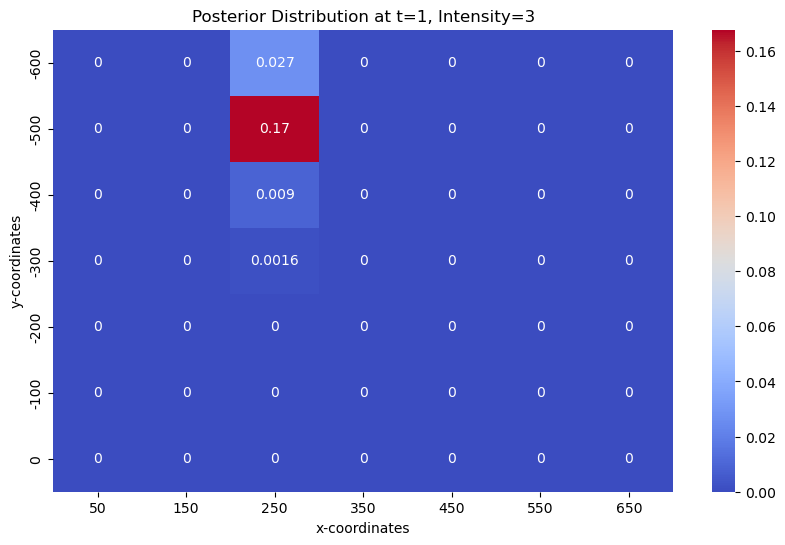

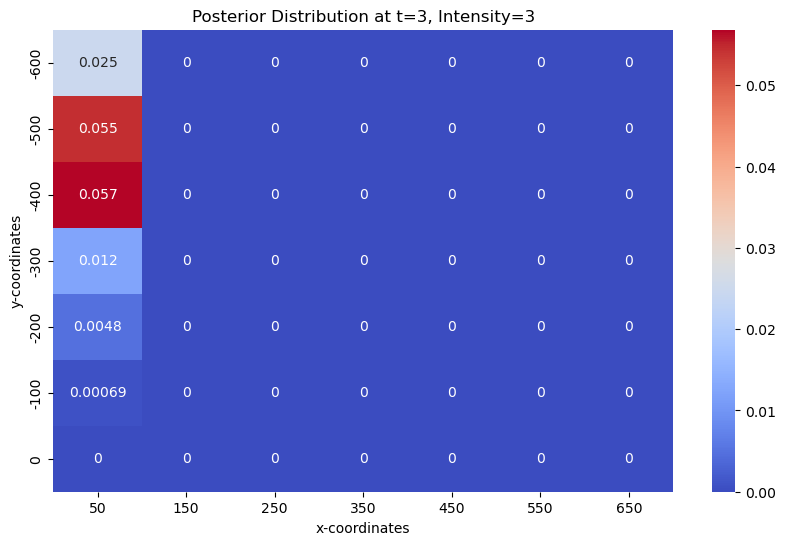

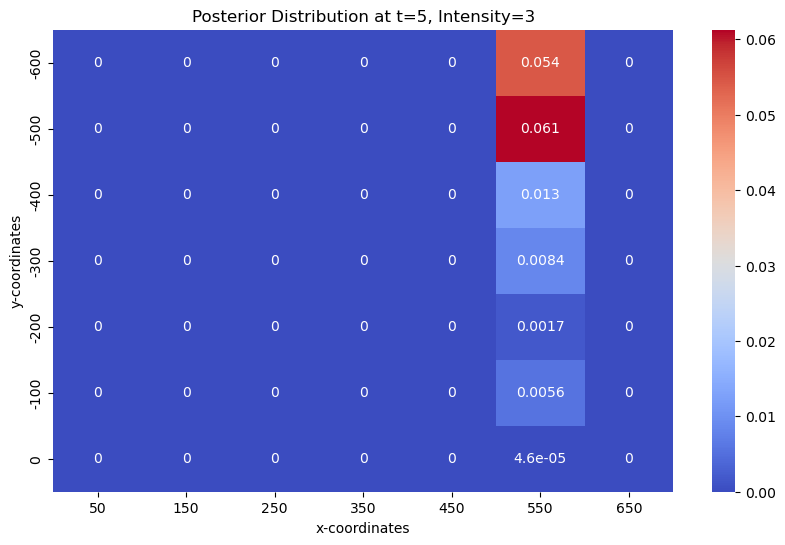

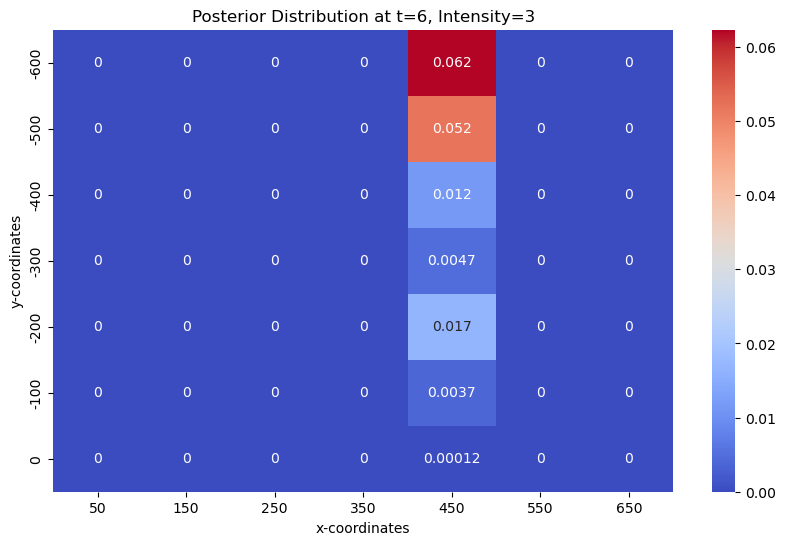

In [15]:
# Set intensity level to track (e.g., intensity=1 or any other)
selected_intensity = 3

# Define a function to plot heatmaps for different time steps
def plot_heatmap(time_step, posterior_3d, selected_intensity):
    posterior_2d = posterior_3d[:, :, selected_intensity]  # Extract x, y for the selected intensity
    plt.figure(figsize=(10, 6))
    sns.heatmap(posterior_2d, xticklabels=x_coordinates, yticklabels=y_coordinates, cmap="coolwarm", annot=True)
    plt.title(f"Posterior Distribution at t={time_step}, Intensity={selected_intensity}")
    plt.xlabel("x-coordinates")
    plt.ylabel("y-coordinates")
    plt.show()

# Visualize for multiple time steps to track progression towards y = 0
time_steps_to_plot = [1, 3, 5, 6]  # Adjust time steps based on your data

for time_step in time_steps_to_plot:
    plot_heatmap(time_step, reshaped_posteriors[time_step - 1], selected_intensity)

In [ ]:
total_prob_y0 = []

for t_step in range(len(reshaped_posteriors)):
    posterior_3d = reshaped_posteriors[t_step]
    total_prob_at_y0 = np.sum(posterior_3d[:, -1, :])  # Sum of all x-coordinates and intensities where y=0
    total_prob_y0.append(total_prob_at_y0)

# Plot total probability at y = 0 over time
plt.plot(range(1, len(total_prob_y0) + 1), total_prob_y0)
plt.xlabel('Time step')
plt.ylabel('Total Probability at y=0')
plt.title('Convergence towards Absorbing State (y=0)')
plt.show()